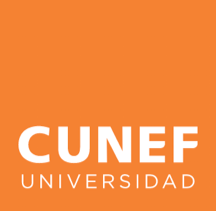
#  <font color=orange> Notebook: 1.4_Exploratory_Data_Analysis</font>
## M2026-27 - Máster of Ciencia de Datos e Inteligencia Artificial (MCDIA-3) 
### Machine Learning [P375]

<b> Professor: </b> Dr. Wolfram Rozas. <b> Department: </b> Quantitiative Methods
___________________________________________________________________________________________

In [17]:
import sys
print(sys.executable)

/opt/anaconda3/envs/G44/bin/python


## 1. What is exploratory data analysis?
Exploratory data analysis (EDA) is the iterative process of investigating a dataset in order to understand its main characteristics, detect patterns and relationships between variables, and identify anomalies or outliers. Through statistical and visualization techniques, exploratory data analysis allows us to formulate hypotheses, guide subsequent analyses, and perform the manipulations needed to later build a machine learning model.

**Goals of exploratory data analysis:**
- **Understand the data:** Gain a general understanding of the dataset and its main characteristics.
- **Identify patterns:** Identify patterns such as trends and relationships between variables.
- **Detect anomalies:** Detect outliers, erroneous data, or data that require further investigation.
- **Formulate hypotheses:** Provide ideas for posing questions and hypotheses that can later be confirmed or refuted using more formal statistical methods.
- **Assess data quality:** Evaluate the quality of the data and identify potential problems, such as biases, missing or erroneous data, before carrying out more advanced analyses.

The conclusions drawn during exploratory analysis often translate into data manipulations that are required before machine learning algorithms can be applied. This manipulation or transformation of the data is known as **preprocessing**.

It is important that preprocessing is carried out properly and explicitly. This means that any transformation of the data must be documented and justified.

## 2. Getting started
We will look at concrete examples alongside the theory, so we begin by importing the libraries we will need:

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

We load the data. This is a real estate dataset. The file `data_description.txt` contains a description of each field.

We start by looking at the dimensions of the file and its columns.

In [19]:
df = pd.read_csv("train.csv")

df.shape

(1460, 81)

In [20]:
df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

We look at the contents of the first rows:

In [21]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [22]:
df.dtypes

Id                 int64
MSSubClass         int64
MSZoning             str
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType             str
SaleCondition        str
SalePrice          int64
Length: 81, dtype: object

In [23]:
df.dtypes.to_dict()

{'Id': dtype('int64'),
 'MSSubClass': dtype('int64'),
 'MSZoning': <StringDtype(na_value=nan)>,
 'LotFrontage': dtype('float64'),
 'LotArea': dtype('int64'),
 'Street': <StringDtype(na_value=nan)>,
 'Alley': <StringDtype(na_value=nan)>,
 'LotShape': <StringDtype(na_value=nan)>,
 'LandContour': <StringDtype(na_value=nan)>,
 'Utilities': <StringDtype(na_value=nan)>,
 'LotConfig': <StringDtype(na_value=nan)>,
 'LandSlope': <StringDtype(na_value=nan)>,
 'Neighborhood': <StringDtype(na_value=nan)>,
 'Condition1': <StringDtype(na_value=nan)>,
 'Condition2': <StringDtype(na_value=nan)>,
 'BldgType': <StringDtype(na_value=nan)>,
 'HouseStyle': <StringDtype(na_value=nan)>,
 'OverallQual': dtype('int64'),
 'OverallCond': dtype('int64'),
 'YearBuilt': dtype('int64'),
 'YearRemodAdd': dtype('int64'),
 'RoofStyle': <StringDtype(na_value=nan)>,
 'RoofMatl': <StringDtype(na_value=nan)>,
 'Exterior1st': <StringDtype(na_value=nan)>,
 'Exterior2nd': <StringDtype(na_value=nan)>,
 'MasVnrType': <StringDty

We check whether the year of sale is correct:

In [24]:
df["YrSold"].value_counts()

YrSold
2009    338
2007    329
2006    314
2008    304
2010    175
Name: count, dtype: int64

## 3. Erroneous values
Erroneous values are values that represent an invalid value for the attribute.

Not to be confused with atypical values or outliers, which we will discuss later.

### 3.1 Example

| name | year | theme | adult | budget |
|---|---|---|---|---|
| _ | 1997 | Family | no | 20.0 |
| The Lion King | "the 90s" | Family | no | 45.0 |
| American History X | 1998 | Action | yes | NA |
| The Usual Suspects | 95 | Mystery | yes | 6.0 |
| Toy Story | 1995 | Family | no | 30,0 |
| Princess Mononoke | 1997 | Family | red | 2400.0 |

### 3.2 Causes
Erroneous values may be due to:

- **Missing values:** values that could not be obtained, or that were lost in the process. They are usually found in the following formats:
  - `NA`: Not Available
  - `?`: Unknown
  - `NaN`: Not a Number
  - ` `: Empty value
- **Incorrect format:** values that do not match the attribute's format and could not be corrected.
- **Measurement errors:** values that fall outside the reasonable range of the attribute.
- **Encoding errors:** values that do not match the attribute's encoding format and may therefore cause errors when read.
- **Non-existent category:** values that do not belong to the attribute's categories.

| name | year | theme | adult | budget |
|---|---|---|---|---|
| _ | 1997 | Family | no | 20.0 |
| The Lion King | "the 90s" | Family | no | 45.0 |
| American History X | 1998 | Action | yes | NA |
| The Usual Suspects | 95 | Mystery | yes | 6.0 |
| Toy Story | 1995 | Family | no | 30,0 |
| Princess Mononoke | 1997 | Family | red | 2400.0 |

### 3.3 Correction
Erroneous values must be corrected or removed so that they do not affect machine learning.

Different strategies are:
- **Remove:** remove the data containing erroneous values.
- **Correct:** correct values that are erroneous in format or measurement, as long as the corrected value can be inferred unambiguously.
- **Impute:** replace the erroneous value with an "appropriate" value for the attribute:
  - Replace it with the Mean / Median / Mode.
  - Replace it with a fixed value, or with a random value within the attribute's measurement range.
  - Estimate the erroneous value with a machine learning model.

### 3.4 Example

| value | new value | Correction |
|---|---|---|
| _ | _ | Remove |
| "the 90s" | 1997 | Impute: Mean |
| NA | NA | Remove |
| 95 | 1995 | Correction |
| 30,0 | 30.0 | Correction |
| red | no | Impute: Mode |

### 3.5 Implementation
We identify missing values:

In [25]:
# pd.isnull returns a bool or an array-like of bool. Summing gives the number of null values per column, as a Series.
pd.isnull(df).sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [26]:
pd.isnull(df[[x for x in df.columns[pd.isnull(df).any()].tolist()]]).sum()

LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64

In [27]:
df[df.isna().any(axis=1)][[x for x in df.columns[pd.isnull(df).any()]]]

,LotFrontage,Alley,MasVnrType,MasVnrArea,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,Electrical,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageQual,GarageCond,PoolQC,Fence,MiscFeature
0,65.0,NaN,BrkFace,196.0,Gd,TA,No,GLQ,Unf,SBrkr,NaN,Attchd,2003.0,RFn,TA,TA,NaN,NaN,NaN
1,80.0,NaN,NaN,0.0,Gd,TA,Gd,ALQ,Unf,SBrkr,TA,Attchd,1976.0,RFn,TA,TA,NaN,NaN,NaN
2,68.0,NaN,BrkFace,162.0,Gd,TA,Mn,GLQ,Unf,SBrkr,TA,Attchd,2001.0,RFn,TA,TA,NaN,NaN,NaN
3,60.0,NaN,NaN,0.0,TA,Gd,No,ALQ,Unf,SBrkr,Gd,Detchd,1998.0,Unf,TA,TA,NaN,NaN,NaN
4,84.0,NaN,BrkFace,350.0,Gd,TA,Av,GLQ,Unf,SBrkr,TA,Attchd,2000.0,RFn,TA,TA,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,62.0,NaN,NaN,0.0,Gd,TA,No,Unf,Unf,SBrkr,TA,Attchd,1999.0,RFn,TA,TA,NaN,NaN,NaN
1456,85.0,NaN,Stone,119.0,Gd,TA,No,ALQ,Rec,SBrkr,TA,Attchd,1978.0,Unf,TA,TA,NaN,MnPrv,NaN
1457,66.0,NaN,NaN,0.0,TA,Gd,No,GLQ,Unf,SBrkr,Gd,Attchd,1941.0,RFn,TA,TA,NaN,GdPrv,Shed
1458,68.0,NaN,NaN,0.0,TA,TA,Mn,GLQ,Rec,FuseA,NaN,Attchd,1950.0,Unf,TA,TA,NaN,NaN,NaN


Let us look at the `Alley` column. 1369 of the 1460 rows have no value in this column, i.e., most of the dataset. Therefore, we do not want to remove all these rows. In the remaining rows, it takes the following values:

In [28]:
df["Alley"].value_counts()

Alley
Grvl    50
Pave    41
Name: count, dtype: int64

We can see that of the three possible values of this variable, `Grvl`, `Pave` and `NA`, the last one never appears. Moreover, it means having no alley, so in this case we can assume that the correct value would be `NA`. To prevent Python from confusing these values with missing values, we replace the missing values with the string `No`:

In [29]:
df["Alley"] = df["Alley"].fillna("No")

df["Alley"].value_counts()

Alley
No      1369
Grvl      50
Pave      41
Name: count, dtype: int64

## 4. Outliers
Outliers are values that deviate greatly from the distribution of the data.

These values can have a major impact on the future model. For this reason, it is usually important to detect them and handle them appropriately.

### 4.1 Detection
Outlier detection is carried out using statistical tools. In many cases, this detection is subjective and depends on the context.

Some ways to detect outliers are:
- If a value lies more than N standard deviations from the mean (e.g. N=3).
- If a value lies in the highest or lowest P percentile (e.g. P=95).
- If the probability of a value occurring in the distribution is less than R (e.g. R=0.01).

### 4.2 Treatment
In many of these cases, outliers are usually treated the same way as erroneous values. For example, if it is a numerical value such as age and an instance takes the value 200.

### 4.3 Example

| name | year | theme | adult | budget |
|---|---|---|---|---|
| Life Is Beautiful | 1997 | Family | no | 20.0 |
| The Lion King | 1994 | Family | no | 45.0 |
| American History X | 1998 | Action | yes | 20.0 |
| The Usual Suspects | 1995 | Mystery | yes | 6.0 |
| Toy Story | 1995 | Family | no | 30.0 |
| Princess Mononoke | 1997 | Family | no | 2400.0 |

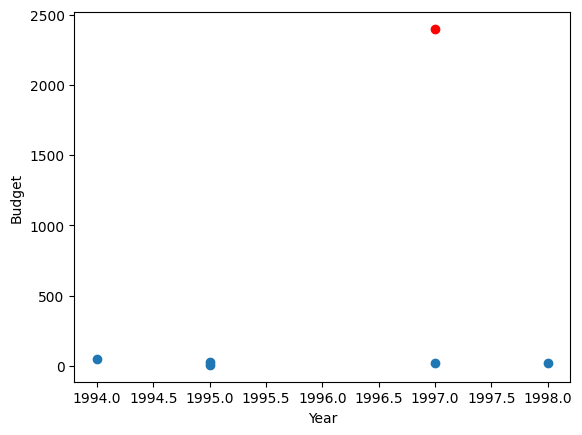

In [30]:
data = [[1997, 20.0], [1994, 45.0], [1998, 20.0], [1995, 6.0], [1995, 30.0]]
plt.scatter([x[0] for x in data], [x[1] for x in data])
outlier = [1997, 2400.0]
plt.scatter([outlier[0]], [outlier[1]], color='red')
plt.xlabel("Year")
plt.ylabel("Budget")
plt.show()

In this case, the value 2400.0 appears to be an outlier. We can statistically quantify how far it deviates from the distribution of the data (excluding the outlier).

In [31]:
avg = sum([x[1] for x in data]) / len(data)
print(f"Mean: {avg}")

Mean: 24.2


In [32]:
std = (sum([(x[1] - avg)**2 for x in data]) / len(data))**0.5
print(f"Std: {std}")

Std: 12.905812643921342


In [33]:
diff = (2400.0 - avg) / std
print(f"Deviations from the mean: {diff}")

Deviations from the mean: 184.08759413681756


The value is clearly an outlier, as it lies more than 5 standard deviations from the mean.

Let us do the same with our housing dataset. We look at the `SalePrice` variable, which is numerical and has no missing values.

In [34]:
df[["SalePrice"]].describe()

,SalePrice
count,1460.000000
mean,180921.195890
std,79442.502883
min,34900.000000
25%,129975.000000
50%,163000.000000
75%,214000.000000
max,755000.000000


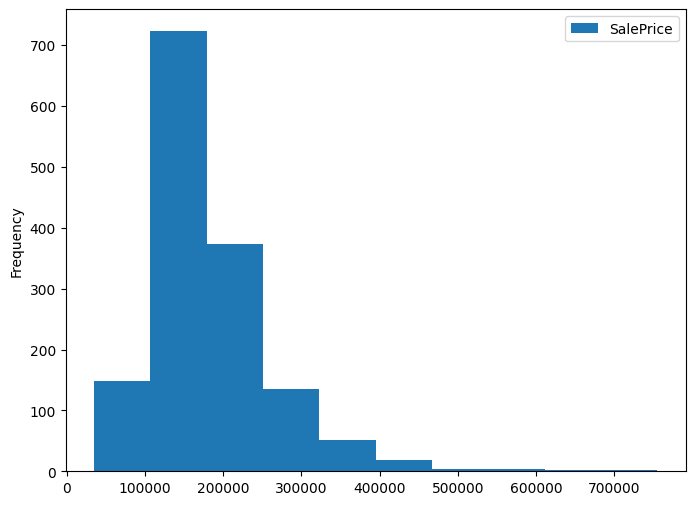

In [35]:
ax = df.plot.hist(column=["SalePrice"], figsize=(8, 6))

In this case, the maximum value is more than 7 standard deviations above the mean. However, the distribution has a fairly long tail, so it does not appear to be an outlier.

## 5. Testing hypotheses
**Example:** How much more expensive are homes with kitchen quality >1 and 2 or more garage spaces than those with quality <=1 and 1 garage space? Compare the means and quartiles of both cases and plot histograms of the sale prices of both groups. Interpret the results.

The variables we need for this are `KitchenAbvGr` and `GarageCars`.

In [36]:
df['KitchenAbvGr'].value_counts()

KitchenAbvGr
1    1392
2      65
3       2
0       1
Name: count, dtype: int64

In [37]:
df.loc[:,['SalePrice']][(df['KitchenAbvGr']>1) & (df['GarageCars']>=2)].describe()

,SalePrice
count,45.000000
mean,133915.555556
std,31752.302862
min,87000.000000
25%,110000.000000
50%,135000.000000
75%,145000.000000
max,206300.000000


In [38]:
df.loc[:,['SalePrice']][(df['KitchenAbvGr']<=1) & (df['GarageCars']==1)].describe()

,SalePrice
count,362.000000
mean,128373.364641
std,30596.789651
min,35311.000000
25%,111250.000000
50%,128100.000000
75%,142093.750000
max,266500.000000


<Axes: xlabel='SalePrice'>

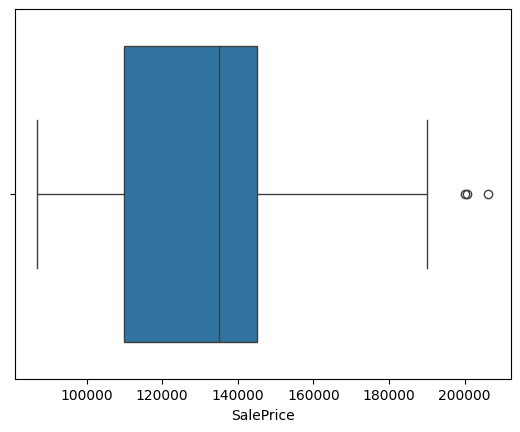

In [39]:
df_1 = df.loc[:,["SalePrice"]][(df["KitchenAbvGr"]>1) & (df["GarageCars"]>=2)].copy()

df_2 = df.loc[:,["SalePrice"]][(df["KitchenAbvGr"]<=1) & (df["GarageCars"]==1)].copy()

sns.boxplot(x=df_1["SalePrice"])

<Axes: xlabel='SalePrice'>

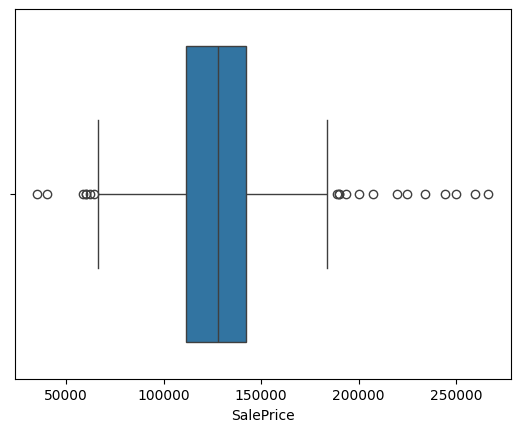

In [40]:
sns.boxplot(x=df_2["SalePrice"])

## 6. Correlation
We can compute the correlation between the numerical variables.

In [41]:
df.corr(numeric_only=True)

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


<Axes: >

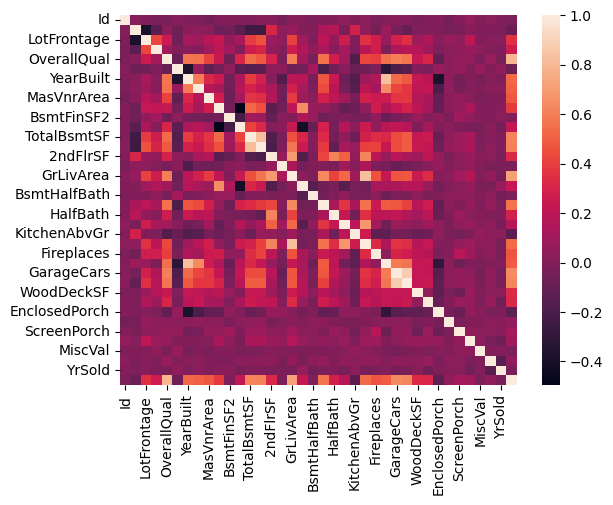

In [42]:
corr = df.corr(numeric_only=True)
sns.heatmap(corr)

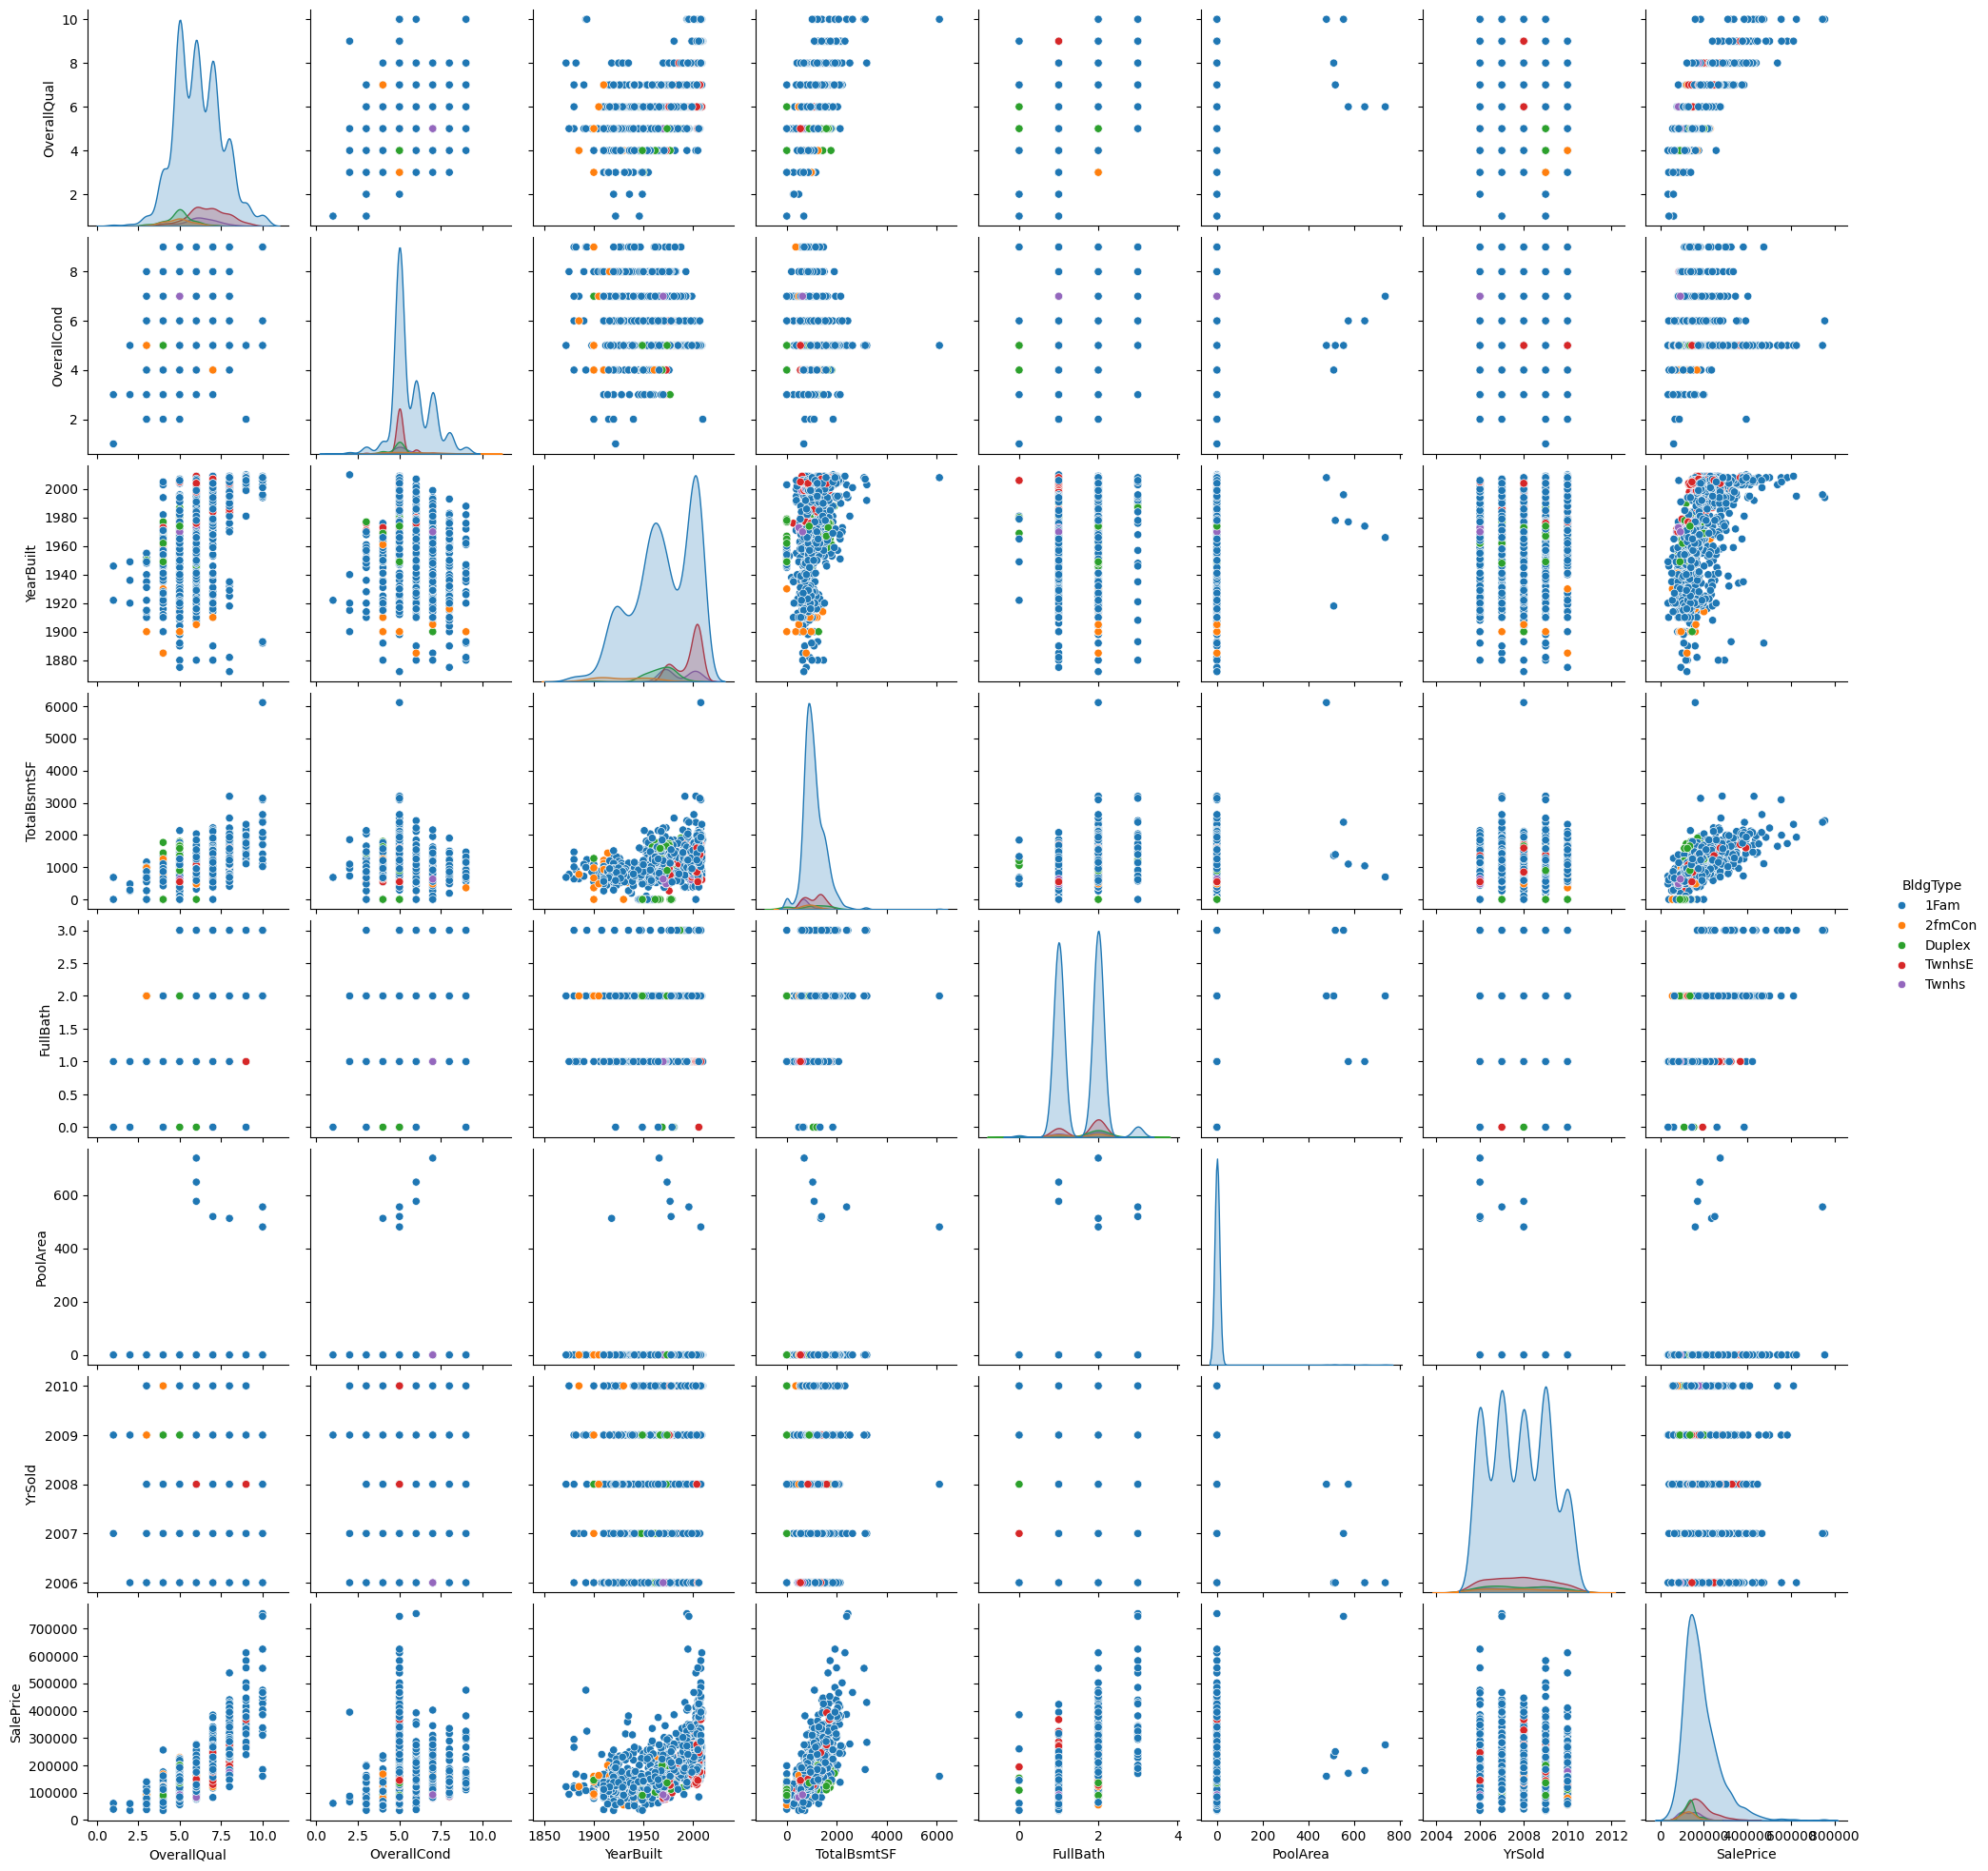

In [43]:
## Visualizing attribute relationships by property type

my_columns = ['MSZoning', 'Neighborhood', 'BldgType',
       'OverallQual', 'OverallCond', 'YearBuilt', 'TotalBsmtSF', 'FullBath',
       'PoolArea', 'YrSold', 'SalePrice']

sns.pairplot(df[my_columns], hue="BldgType")

## 7. Normalization
### 7.1 Normalization
Normalization is a process that consists of transforming numerical data so that they satisfy certain properties.
- **Range:** the values of an attribute must lie within a given range.
- **Unit:** the values of an attribute must be in the same unit.
- **Scale:** the values of different attributes must be in the same proportion or scale.

### 7.2 Importance
We have already seen that several algorithms depend on the distance between data points. Different scales or ranges can greatly affect the importance of each attribute in the model.

Text(0.5, 1.0, 'scale 0.02252252252252252:1')

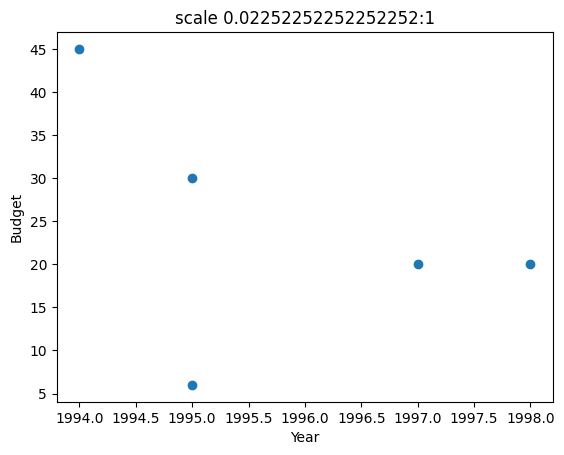

In [44]:
plt.scatter([x[0] for x in data], [x[1] for x in data])
plt.xlabel("Year")
plt.ylabel("Budget")
max_value_0 = max([x[0] for x in data])
max_value_1 = max([x[1] for x in data])
max_value = max(max_value_0, max_value_1)
scale = max_value_1 / max_value_0
plt.title(f"scale {scale}:1")

Text(0.5, 1.0, 'scale 1:1')

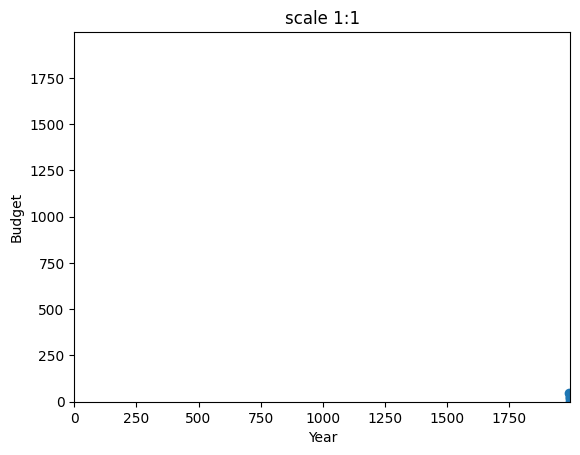

In [45]:
plt.scatter([x[0] for x in data], [x[1] for x in data])
_ = plt.xlim(0, max_value)
_ = plt.ylim(0, max_value)
plt.xlabel("Year")
plt.ylabel("Budget")
plt.title("scale 1:1")

### 7.3 Techniques
There are various normalization techniques. We will work with the 2 most common ones:
- **Standardization:** transforming the data so that they have a specific mean and standard deviation.
- **Scaling:** transforming the data so that they fall within a given range.

#### 7.3.1 Standardization
Standardization consists of transforming the data so that they have a specific mean and standard deviation. Generally, a mean of 0 and a standard deviation of 1 are used.

Where $\mu$ is the mean of the attribute and $\sigma$ is the standard deviation of the attribute, the standardization that transforms each data point $x$ is:

$$x' = \frac{x - \mu}{\sigma}$$

#### 7.3.2 Scaling
Scaling consists of transforming the data so that they fall within a given range. Generally, the range $[0,1]$ is used.

Where $min$ and $max$ are the minimum and maximum of the attribute, and $min'$ and $max'$ are the minimum and maximum of the target range, the scaling that transforms each data point $x$ is:

$$x' = \frac{x - min}{max - min} \cdot (max' - min') + min'$$

### 7.4 Example

In [46]:
avg_year = sum([x[0] for x in data]) / len(data)
std_year = (sum([(x[0] - avg_year)**2 for x in data]) / len(data))**0.5
avg_budget = sum([x[1] for x in data]) / len(data)
std_budget = (sum([(x[1] - avg_budget)**2 for x in data]) / len(data))**0.5
print(f"Mean year: {avg_year}, Std. dev. year: {std_year}")
print(f"Mean budget: {avg_budget}, Std. dev. budget: {std_budget}")

Mean year: 1995.8, Std. dev. year: 1.469693845669907
Mean budget: 24.2, Std. dev. budget: 12.905812643921342


In [47]:
data_1 = pd.DataFrame(data, columns=["year", "budget"])
data_1["year (scaled [0,1])"] = (data_1["year"] - data_1["year"].min()) / (data_1["year"].max() - data_1["year"].min())

data_1["budget (standardized)"] = (data_1["budget"] - data_1["budget"].mean()) / data_1["budget"].std()

print(data_1)

   year  budget  year (scaled [0,1])  budget (standardized)
0  1997    20.0                 0.75              -0.291078
1  1994    45.0                 0.00               1.441528
2  1998    20.0                 1.00              -0.291078
3  1995     6.0                 0.25              -1.261337
4  1995    30.0                 0.25               0.401964


## 8. Disaggregation
### 8.1 Disaggregation
Disaggregation is a process that consists of transforming categorical data into numerical attributes.

This is important because many machine learning algorithms can only work with numerical data (e.g. computing distances).

### 8.2 Considerations
Several considerations must be taken into account before encoding categorical data:
1. **Number of categories:** the number of categories must be finite and known, since adding new categories afterward can be problematic.
2. **Relationship between categories:** assigning a number to each category implies that there is an order relationship between them. This is not always true, and can therefore be misleading. E.g. converting cities into numbers creates false relationships between cities.

### 8.3 Techniques
Depending on the type of category, there are different techniques:
- **Label encoding:** a number is assigned to each category.
- **One-hot encoding:** an attribute is created for each category, assigning 1 to the attribute of the corresponding category and 0 to the rest.

### 8.4 Label encoding
With this technique, a number is assigned to each category.

This technique is appropriate when one of these conditions is met:
- there is an order relationship between the categories.
- it is a binary category (it only has 2 possible values).
- the number of possible categories is undetermined.

| adult | nAdult |
|---|---|
| no | 0 |
| no | 0 |
| yes | 1 |
| yes | 1 |
| no | 0 |
| no | 0 |

### 8.5 One-hot encoding
This technique creates new attributes or columns for each category. In this way, each new attribute is understood as *data point x belongs to category y*.

This technique does not create an order relationship between categories. We can consider the difference or distance from each category to any other to be the same.

This technique is appropriate when:
- there is no order relationship between the categories
- and there are more than 2 possible categories
- and the number of categories is known in advance.

| theme | tFamily | tAction | tMystery |
|---|---|---|---|
| Family | 1 | 0 | 0 |
| Family | 1 | 0 | 0 |
| Action | 0 | 1 | 0 |
| Mystery | 0 | 0 | 1 |
| Family | 1 | 0 | 0 |
| Family | 1 | 0 | 0 |

## 9. Categorization
### 9.1 Categorization
In contrast to disaggregation, categorization is a process that consists of transforming numerical data into categorical attributes. This may be necessary for certain algorithms that can only work with categorical data.

Which categories are assigned to the numerical data is a subjective and context-dependent process.

### 9.2 Example

| year | cYear |
|---|---|
| 1997 | 90s |
| 1984 | 80s |
| 1988 | 80s |
| 2005 | 2000 |
| 2005 | 2000 |

In [48]:
pd.cut(df["SalePrice"], bins=5).value_counts()

SalePrice
(34179.9, 178920.0]     871
(178920.0, 322940.0]    508
(322940.0, 466960.0]     70
(466960.0, 610980.0]      7
(610980.0, 755000.0]      4
Name: count, dtype: int64

## 10. Conclusions
### 10.1 Conclusions
- A fundamental part of the machine learning process is the dataset.
- Data must be preprocessed before it can be used in machine learning algorithms.
- Preprocessing must be explicit, justified, and documented.
- Preprocessing techniques:
  - Correcting erroneous values: remove, correct, or impute.
  - Correcting outliers: detect, remove, correct, or impute.
  - Normalization: standardization or scaling.
  - Disaggregation: label encoding or one-hot encoding.
  - Categorization: choosing categories.